# 06 · Modelo final: tuning, explicabilidade e calibração

Escolhido o LightGBM, este notebook:
1. **ajusta os hiperparâmetros** com otimização bayesiana (Optuna) na validação cruzada temporal;
2. **explica** o modelo (SHAP), para conferir se ele aprendeu padrões de negócio plausíveis;
3. **calibra** as probabilidades, porque decisões por custo esperado exigem que "0,10" signifique
   de fato ~10% de chance de fraude;
4. treina o **modelo final** em treino + validação e salva o artefato de produção.

> Obs.: O período de teste (11/04–21/04) continua intocado.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import time, optuna, shap, lightgbm as lgb
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score
from fraude import validacao
from fraude.features import ConstrutorFeatures
from fraude.inferencia import ModeloFraude, CalibradorPlatt
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
%%time
base = dados.carregar_base()
dev = base[base["particao"] != "teste"].reset_index(drop=True)
folds = validacao.construir_folds(dev)

CPU times: total: 19.8 s
Wall time: 39.5 s


## 1. Tuning de hiperparâmetros

- **Busca:** TPE (bayesiana), 40 tentativas.
- **Objetivo:** PR AUC **médio** nos 3 folds temporais. Otimizar a média entre períodos favorece
  configurações que generalizam no tempo, e não as que acertam uma janela específica.
- **Espaço de busca:** complexidade das árvores (`num_leaves`, `min_child_samples`), regularização
  (`reg_lambda`, `reg_alpha`), amostragem (`subsample`, `colsample_bytree`) e o par
  `learning_rate` × `n_estimators`. 
    - O número de árvores é **tunado diretamente**, sem *early stopping* na janela de validação, para que a métrica do fold não seja usada duas vezes.

In [3]:
PARAMS_FIXOS = dict(subsample_freq=1, random_state=cfg.SEED, verbose=-1, n_jobs=-1)

def objetivo(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 150, 1200, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 400, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )
    r, _ = validacao.avaliar_cv(lgb.LGBMClassifier(**params, **PARAMS_FIXOS), folds)
    trial.set_user_attr("pr_auc_por_fold", r["PR AUC"].round(4).tolist())
    return r["PR AUC"].mean()

estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=cfg.SEED))
# Ponto de partida: a configuração usada no nb 05
estudo.enqueue_trial(dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                          subsample=0.8, colsample_bytree=0.8, reg_lambda=1e-3, reg_alpha=1e-3))
t0 = time.time()
estudo.optimize(objetivo, n_trials=40)
print(f"Tuning concluído em {time.time() - t0:.0f}s | melhor PR AUC médio: {estudo.best_value:.4f}")
pd.Series(estudo.best_params).to_frame("melhores hiperparâmetros").T

Tuning concluído em 172s | melhor PR AUC médio: 0.4214


,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha
melhores hiperparâmetros,650.0000,0.0225,16.0000,59.0000,0.5615,0.9884,13.1452,0.0596


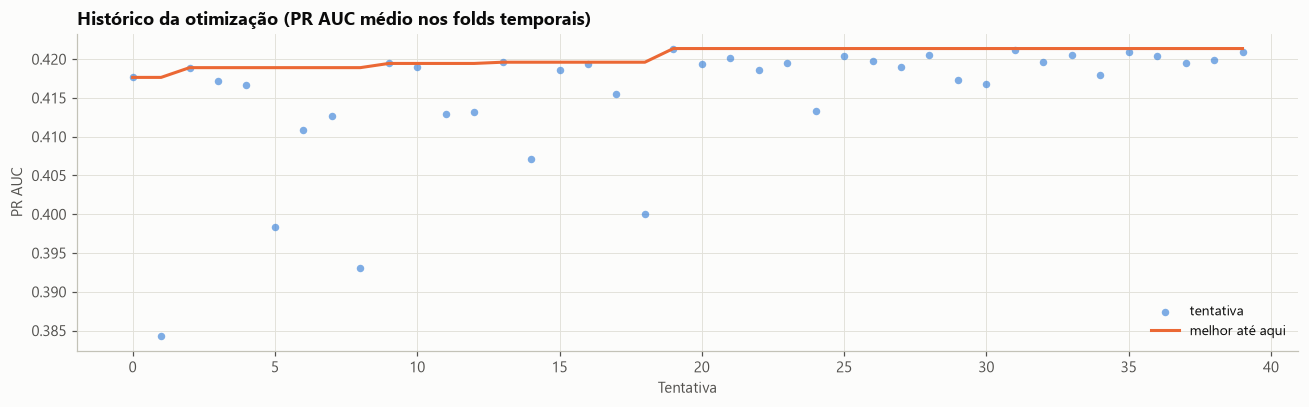

In [4]:
hist = estudo.trials_dataframe()[["number", "value"]]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.scatter(hist["number"], hist["value"], color=gr.AZUL, s=24, alpha=0.6, label="tentativa")
ax.plot(hist["number"], hist["value"].cummax(), color=gr.LARANJA, label="melhor até aqui")
ax.set(title="Histórico da otimização (PR AUC médio nos folds temporais)", xlabel="Tentativa", ylabel="PR AUC")
ax.legend(loc="lower right")
plt.tight_layout()

In [5]:
melhores = {**estudo.best_params, **PARAMS_FIXOS}
modelo_padrao = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                                   subsample=0.8, colsample_bytree=0.8, **PARAMS_FIXOS)
modelo_tunado = lgb.LGBMClassifier(**melhores)

r_pad, _ = validacao.avaliar_cv(modelo_padrao, folds, nome="LightGBM padrão (nb 05)")
r_tun, oof = validacao.avaliar_cv(modelo_tunado, folds, nome="LightGBM tunado")
comp = pd.concat([r_pad, r_tun])
display(validacao.resumo_cv(comp)[["PR AUC (média)", "PR AUC (dp)", "ROC AUC (média)", "Recall @ FPR 5% (média)"]])
comp.pivot(index="modelo", columns="fold", values="PR AUC").add_prefix("PR AUC fold ")

,PR AUC (média),PR AUC (dp),ROC AUC (média),Recall @ FPR 5% (média)
modelo,,,,
LightGBM tunado,0.4214,0.0098,0.8552,0.4867
LightGBM padrão (nb 05),0.4177,0.0093,0.8534,0.4807


fold,PR AUC fold 1,PR AUC fold 2,PR AUC fold 3
modelo,,,
LightGBM padrão (nb 05),0.4092,0.4277,0.4162
LightGBM tunado,0.4120,0.4315,0.4206


O tuning traz um ganho **razoável**, que é algo comum quando as features já estão bem construídas e o
algoritmo é robusto. 

O ganho precisa aparecer **nos 3 folds** (tabela acima) para não ser "sorte" de
uma janela específica. 

>Portanto, ficamos com a configuração tunada.

## 2. Explicabilidade do modelo

Usamos **SHAP** (TreeSHAP), que decompõe cada predição na contribuição de cada feature. Analisamos o
modelo do fold 3 (treinado até 04/04) sobre a janela de validação 05/04–10/04.

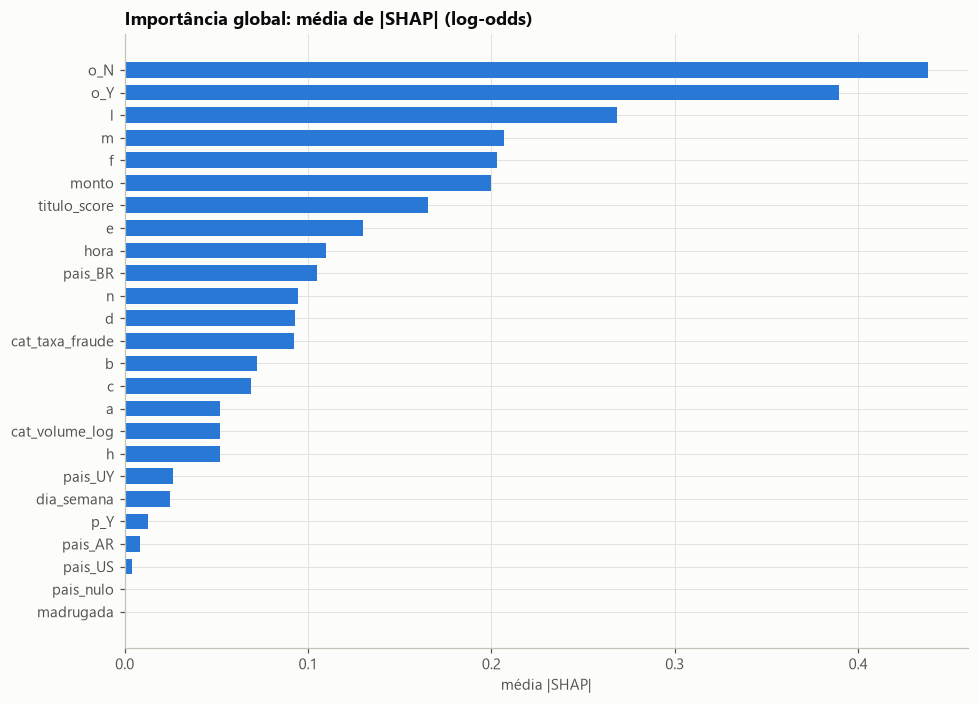

In [6]:
f3 = folds[-1]
m3 = lgb.LGBMClassifier(**melhores).fit(f3.X_tr, f3.y_tr)
amostra = f3.X_va.sample(5000, random_state=cfg.SEED)
explicador = shap.TreeExplainer(m3)
valores_shap = explicador(amostra)

imp = pd.Series(np.abs(valores_shap.values).mean(0), index=amostra.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(imp.index, imp.values, color=gr.AZUL, height=0.7)
ax.set(title="Importância global: média de |SHAP| (log-odds)", xlabel="média |SHAP|")
plt.tight_layout(); plt.show()

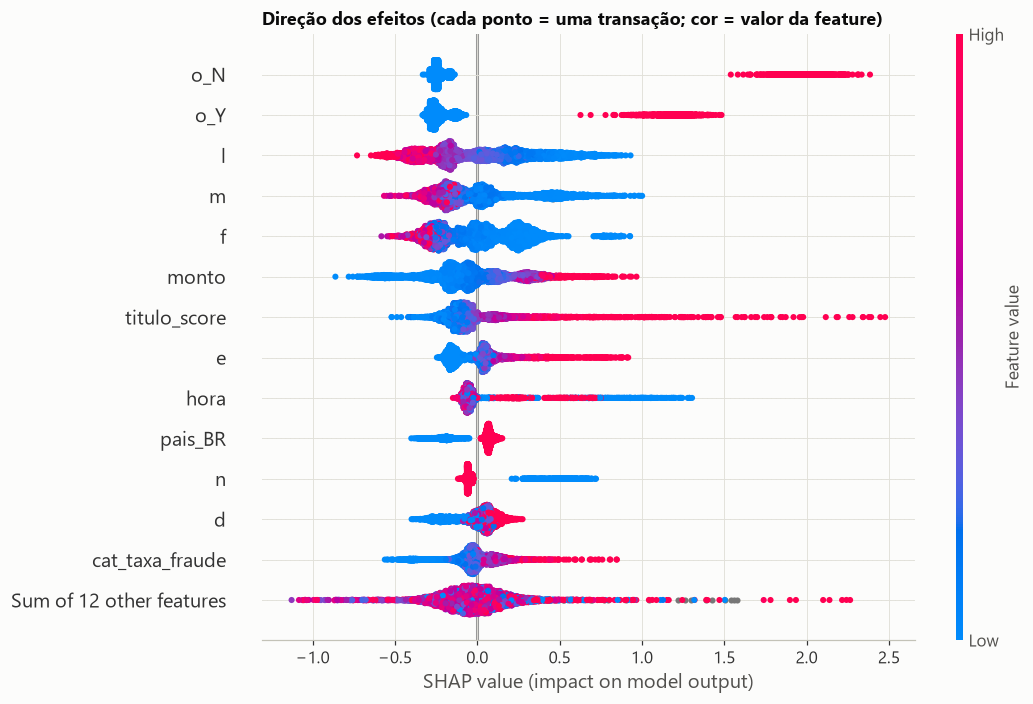

In [7]:
plt.figure()
shap.plots.beeswarm(valores_shap, max_display=14, show=False, plot_size=(10, 6.5))
plt.title("Direção dos efeitos (cada ponto = uma transação; cor = valor da feature)", loc="left")
plt.tight_layout()

**Os padrões aprendidos batem com a EDA e com a intuição de negócio:**
- **`o`** é o sinal mais forte: `o = N` (e, em menor grau, `o = Y`) empurra o risco para cima em
  relação ao nulo;
- **`l`, `m`, `f` baixos aumentam o risco**, compatível com contas novas ou com pouco histórico;
- **`monto` e `e`**: valores altos elevam o risco;
- **`titulo_score` e `cat_taxa_fraude`**: produtos visados (celulares, gift cards) elevam o risco;
- **`hora`** baixa (madrugada) e **`n = 0`** elevam o risco;

Nenhuma variável "estranha" domina o modelo, o que é um bom sinal de ausência de vazamento.

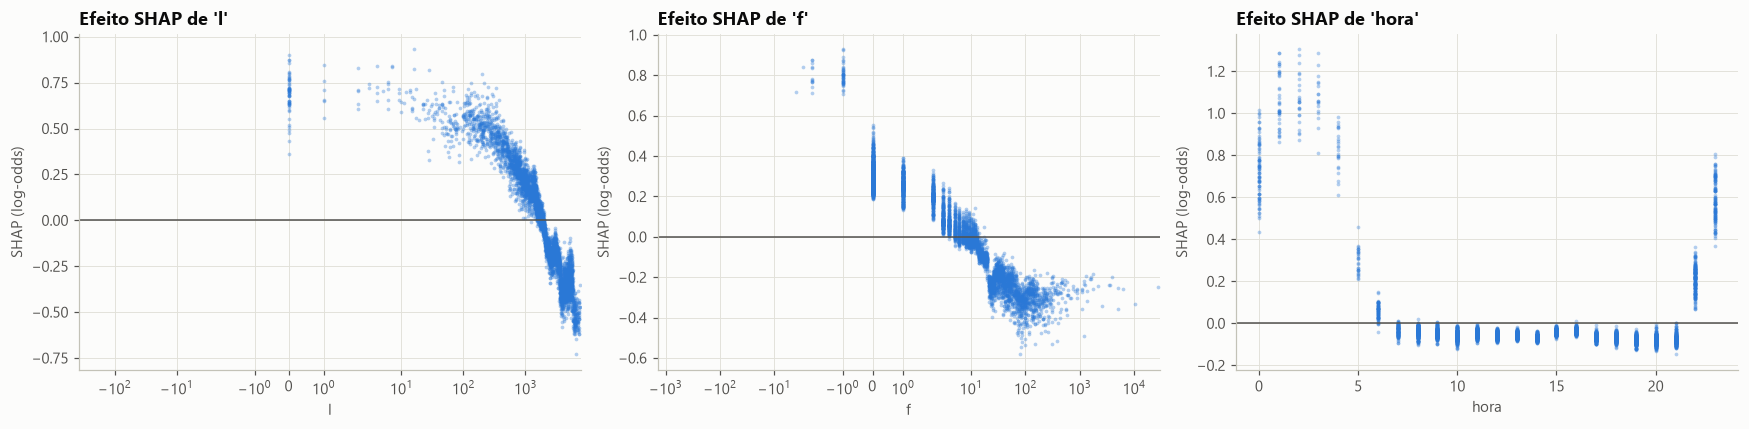

In [8]:
# Dependência: como o risco varia com as duas principais variáveis numéricas
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["l", "f", "hora"]):
    x = amostra[col]; sv = valores_shap[:, col].values
    ax.scatter(x, sv, s=6, alpha=0.35, color=gr.AZUL)
    ax.axhline(0, color=gr.TINTA_2, lw=1)
    ax.set(title=f"Efeito SHAP de '{col}'", xlabel=col, ylabel="SHAP (log-odds)")
    if col in ("l", "f"):
        ax.set_xscale("symlog")
plt.tight_layout()

As curvas de dependência confirmam as **não linearidades** vistas na EDA. 

O risco despenca nos primeiros valores de `l` e `f` e depois estabiliza. 

Na `hora`, há um "vale" de risco durante o dia e um pico de madrugada. 

> Um modelo linear **não representaria** esses formatos sem engenharia manual!

**Explicação individual** (útil para a área de fraudes): os motivos
de uma transação de alto risco.

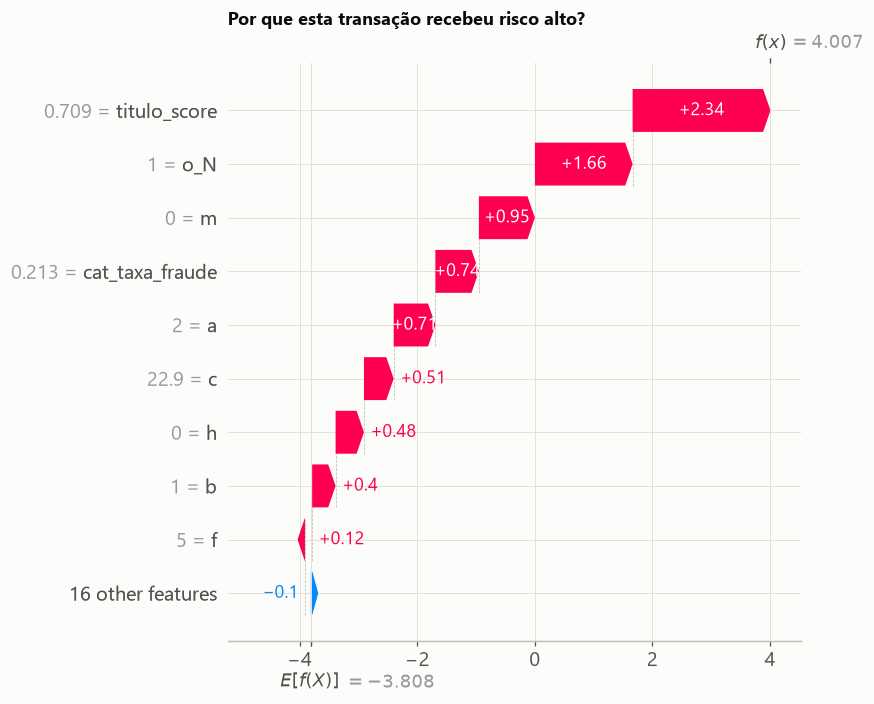

In [9]:
i_alto = np.argmax(m3.predict_proba(amostra)[:, 1])
plt.figure()
shap.plots.waterfall(valores_shap[i_alto], max_display=10, show=False)
plt.title("Por que esta transação recebeu risco alto?", loc="left")
plt.tight_layout(); plt.show()

## 3. Ajuste de calibração das probabilidades *(pergunta 5)*

A ideia é que o score do modelo não represente apenas uma **faixa de risco** ou uma **pontuação para ordenar transações**, mas também uma **estimativa da probabilidade de fraude** para transações com características e scores semelhantes.

- Exemplificando, se o modelo atribui score de 80% para 1.000 transações e está bem calibrado, esperamos que, dessas 1.000 transações:
    - Aproximadamente 800 sejam efetivamente fraudes;
    - Aproximadamente 200 sejam legítimas.

Isso é especialmente importante para compararmos **probabilidade × custo** (próximo passo), já que a saída do modelo precisa ser uma probabilidade confiável.

Portanto, usamos as predições *out-of-fold* temporais (cada janela prevista por um
modelo que só viu o passado) para:
1. diagnosticar a calibração vigente do modelo bruto;
2. escolher e ajustar um **calibrador** sobre as predições das dobras 1–2 e medir na dobra 3 (mapeamento de score para probabilidade).

Prob. média prevista: 0.0496 | taxa real nas janelas OOF: 0.0565
Brier score (bruto): 0.04159


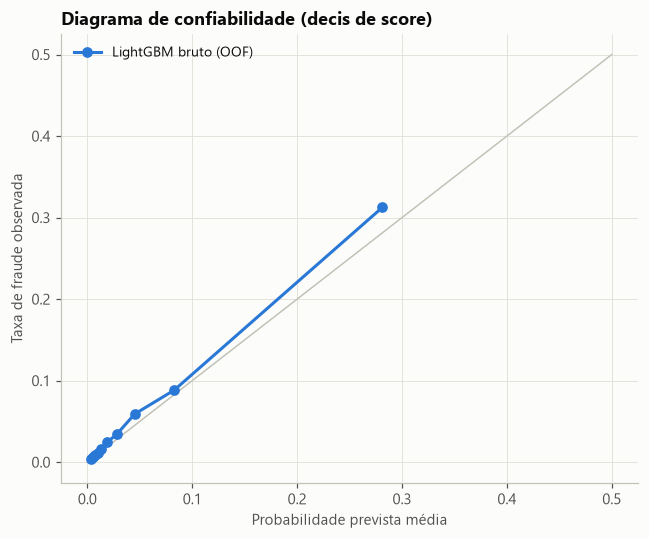

In [10]:
def tabela_confiabilidade(y, p, bins=10):
    faixa = pd.qcut(p, bins, duplicates="drop")
    return pd.DataFrame({"prevista": p, "real": y}).groupby(faixa, observed=True).mean()

conf_bruta = tabela_confiabilidade(oof["y"], oof["p"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 0.5], [0, 0.5], color=gr.EIXO, lw=1)
ax.plot(conf_bruta["prevista"], conf_bruta["real"], marker="o", color=gr.AZUL, label="LightGBM bruto (OOF)")
ax.set(title="Diagrama de confiabilidade (decis de score)", xlabel="Probabilidade prevista média",
       ylabel="Taxa de fraude observada")
ax.legend()
plt.tight_layout()
print(f"Prob. média prevista: {oof['p'].mean():.4f} | taxa real nas janelas OOF: {oof['y'].mean():.4f}")
print(f"Brier score (bruto): {brier_score_loss(oof['y'], oof['p']):.5f}")
plt.show()

O modelo bruto (treinado sem pesos) já é **razoavelmente calibrado**, mas **subestima levemente** o
risco, pois a probabilidade média prevista (~5,0%) fica abaixo da taxa observada (~5,7%). 

A causa disso é temporal, pois a taxa de fraude subiu entre o período de treino e as janelas de validação, ou seja, um
*prior shift*.

**Qual calibrador?** Comparamos duas opções clássicas:
- **Isotônica**
- **Platt sobre o logit**.

E avaliamos o **Brier score**, que representa **o quanto as probabilidades de fraude previstas pelo modelo estão próximas dos resultados que realmente aconteceram** (quanto mais próximo de zero, melhor).

> Nota: **a calibração herda a taxa de fraude do período em que foi ajustada**. Se a
taxa mudar em produção, as probabilidades se deslocam. Por isso a calibração deve ser **monitorada e
reajustada com frequência**, separadamente do modelo.

In [11]:
# Avaliação "honesta" do calibrador: ajusta nos folds 1-2 e mede no fold 3 (futuro)
ajuste, aval = oof[oof["fold"] < 3], oof[oof["fold"] == 3]
opcoes = {"Isotônica": IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1), "Platt (logit)": CalibradorPlatt()}
linhas = [{"calibrador": "Nenhum (bruto)", "Brier (fold 3)": brier_score_loss(aval["y"], aval["p"]),
           "PR AUC (fold 3)": average_precision_score(aval["y"], aval["p"]), "prob. média": aval["p"].mean()}]
for nome, c in opcoes.items():
    pc = c.fit(ajuste["p"], ajuste["y"]).predict(aval["p"])
    linhas.append({"calibrador": nome, "Brier (fold 3)": brier_score_loss(aval["y"], pc),
                   "PR AUC (fold 3)": average_precision_score(aval["y"], pc), "prob. média": pc.mean()})
print(f"Taxa real de fraude no fold 3: {aval['y'].mean():.4f}")
pd.DataFrame(linhas).set_index("calibrador").style.format("{:.5f}")

Taxa real de fraude no fold 3: 0.0560


,Brier (fold 3),PR AUC (fold 3),prob. média
calibrador,,,
Nenhum (bruto),0.04123,0.42064,0.05038
Isotônica,0.04114,0.40589,0.05814
Platt (logit),0.04113,0.42064,0.05818


O Platt **preserva integralmente o PR AUC**, enquanto a isotônica perde ordenação com os empates. O
Platt também tem Brier igual ou melhor fora da amostra. 

>**Escolha: Platt**, ajustado em todas as predições out-of-fold.

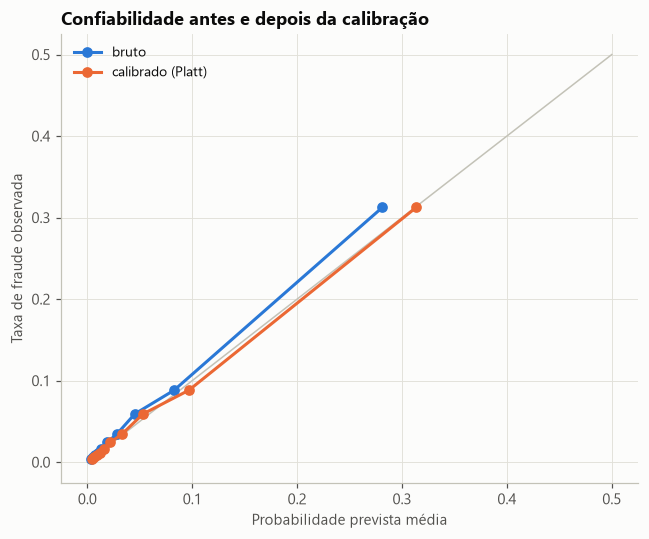

In [12]:
calibrador = CalibradorPlatt().fit(oof["p"], oof["y"])
oof["p_cal"] = calibrador.predict(oof["p"])
conf_cal = tabela_confiabilidade(oof["y"], oof["p_cal"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 0.5], [0, 0.5], color=gr.EIXO, lw=1)
ax.plot(conf_bruta["prevista"], conf_bruta["real"], marker="o", color=gr.AZUL, label="bruto")
ax.plot(conf_cal["prevista"], conf_cal["real"], marker="o", color=gr.LARANJA, label="calibrado (Platt)")
ax.set(title="Confiabilidade antes e depois da calibração", xlabel="Probabilidade prevista média",
       ylabel="Taxa de fraude observada")
ax.legend()
plt.tight_layout(); plt.show()

## 4. Treino do modelo final e artefato de produção *(pergunta 1)*

O modelo final é treinado em **treino + validação** (08/03–10/04), os dados mais recentes disponíveis
antes do teste, com os hiperparâmetros tunados. 

O artefato salvo é um objeto único (`ModeloFraude`)
com construtor de features, LightGBM, calibrador e metadados. 

> Assim, a versão online pode utilizar **exatamente o mesmo código** deste "laboratório".

In [13]:
%%time
construtor = ConstrutorFeatures()
X_dev = construtor.fit_transform(dev, dev["fraude"])
modelo_final = lgb.LGBMClassifier(**melhores).fit(X_dev, dev["fraude"])

artefato = ModeloFraude(
    construtor=construtor, modelo=modelo_final, calibrador=calibrador, limiar=None,
    metadados={
        "versao": "fraude-lgbm-v1",
        "treinado_em": pd.Timestamp.now().isoformat(timespec="seconds"),
        "periodo_treino": [str(dev["fecha"].min()), str(dev["fecha"].max())],
        "n_treino": len(dev), "taxa_fraude_treino": float(dev["fraude"].mean()),
        "features": construtor.feature_names_, "hiperparametros": melhores,
        "cv_pr_auc_medio": float(r_tun["PR AUC"].mean()), "cv_roc_auc_medio": float(r_tun["ROC AUC"].mean()),
    })
cfg.DIR_MODELOS.mkdir(exist_ok=True)
artefato.salvar(cfg.ARQUIVO_MODELO)
print("Artefato salvo:", cfg.ARQUIVO_MODELO.relative_to(cfg.RAIZ),
      f"({cfg.ARQUIVO_MODELO.stat().st_size / 1e6:.1f} MB)")

Artefato salvo: models\modelo_fraude.joblib (3.3 MB)
CPU times: total: 24.2 s
Wall time: 21.4 s


In [14]:
# Predições out-of-fold do período dev: insumo do notebook 08 para escolher o ponto de corte
# sem tocar no teste (o corte é escolhido no passado e aplicado no futuro).
oof_out = dev.loc[oof["idx"], ["fecha", "monto", "score", "fraude"]].reset_index(drop=True)
oof_out["fold"] = oof["fold"].to_numpy()
oof_out["p_bruta"] = oof["p"].to_numpy()
oof_out["p_modelo"] = oof["p_cal"].to_numpy()
oof_out.to_parquet(cfg.ARQUIVO_PRED_OOF, index=False)
oof_out.groupby("fold").agg(inicio=("fecha", "min"), fim=("fecha", "max"), n=("fraude", "size"))

,inicio,fim,n
fold,,,
1,2020-03-22 00:01:45,2020-03-28 23:56:30,20935
2,2020-03-29 00:01:45,2020-04-04 23:58:49,16800
3,2020-04-05 00:01:07,2020-04-10 23:59:43,21000


## 5. Conclusões

- **Modelo:** 
  - LightGBM tunado, treinado em 108 mil
  transações (08/03–10/04) com 25 features.
- **Desempenho esperado (CV temporal):** 
  - **PR AUC ≈ 0,42** e **ROC AUC ≈ 0,85**.
- **Explicabilidade:**
  - Os principais fatores são plausíveis e coerentes com a EDA; 
  - O SHAP também permite **motivos por transação** para o time de operações.
- **Calibração:**
  - Probabilidade bruta próxima do real, corrigida por Platt; 
  - **É sensível a mudanças na taxa de fraude e deve ser monitorada e reajustada.**
- **Artefato:** `models/modelo_fraude.joblib`, contendo features + modelo + calibrador + metadados.